# Start here: shared IPI design and repeatable live tests

Use this notebook to build the repository's **hw/sys.bd ? XSA ? mb BSP ? bench.elf ? demo.pdi** image, then program it and compare new hardware and Python timings inline. The AXI Timer is part of this BD. The image embeds the ELF in BRAM, so **no separate ELF download is required**.

Copy config.example.json to config.json and configure your tool root, short local build directory, exact cable and UART, matching hardware Vivado/server, recovery PDI and SHA-256. The build requires 2026.1; the hardware client must match your server. The local config is ignored by Git.

Close other COM-port terminals and active debug sessions before running LIVE=True. The runtime runner programs only the selected SCU35 and reloads your configured recovery image afterward. It performs no flash or eFUSE writes. Set LIVE=True explicitly for every fresh test; otherwise the output clearly identifies recorded board evidence plus fresh Python timing.

**Saved execution:** 2026-10-26T03:37:29.166038+00:00 (UTC). **fresh file inspection / Python; recorded board evidence**. No new board programming was performed by this notebook execution. Portable defaults below are restored to `LIVE=False`; saved outputs are retained. To repeat on your board, configure it and enable the live flag. Boot outputs show acceptance/recovery and host verification times, not on-chip boot latency.

In [1]:
from pathlib import Path
import sys, os, json, time, hashlib
import pandas as pd
ROOT = next((p for base in [Path.cwd(), *Path.cwd().parents]
             for p in (base, base/'scu35') if (p/'lab.py').is_file()), None)
assert ROOT is not None, 'Open the notebook from the repository checkout'
sys.path.insert(0, str(ROOT)); sys.path.insert(0, str(ROOT/'host'))
from lab import config, tool
from notebook import runtime, show_runtime, LiveRows, command, hardware, check_build
c = config()
OUT = Path(c['build_dir']).resolve()
print('Python:', sys.executable)
print('Build:', OUT)


Python: C:\aiup\pubvenv\Scripts\python.exe
Build: C:\aiup\s35p2


In [2]:
print(json.dumps(c, indent=2))
BUILD_PHASES = []  # Fresh build: ['hardware','platform','firmware','image']
# Use a FRESH short build directory for a new hardware/platform build.
if BUILD_PHASES:
    command('doctor', c=c)
    for phase in BUILD_PHASES:
        command('build','--phase',phase,c=c)
else:
    print('Build skipped; reuse your configured existing repository IPI build.')


{
  "tools": "D:/AMDDesignTools/2026.1",
  "build_dir": "C:/aiup/s35p2",
  "jobs": 2,
  "hardware_vivado": "C:/Xilinx/2025.2/Vivado/bin/vivado.bat",
  "server": "localhost:3121",
  "cable": "52041A454A5PA",
  "serial_port": "COM10",
  "restore_pdi": "C:/xup/scu35/sec_001/sec_001.runs/impl_1/top_wrapper.pdi",
  "restore_sha256": "3edbbaa0eb1373812d032b7090620949e969706c3c6e9e9f3b40a8466abd0020"
}
Build skipped; reuse your configured existing repository IPI build.


In [3]:
INSPECT_BUILD = False
if INSPECT_BUILD:
    pdi = check_build(c)
    command('inspect','--pdi',pdi,'--elf',OUT/'plm.elf',c=c)
    print('Implementation:', (OUT/'implementation_checks.json').read_text())


RUN: inspect --pdi C:\aiup\s35p2\demo.pdi --elf C:\aiup\s35p2\plm.elf


RUN D:\AMDDesignTools\2026.1\Vivado\bin\bootgen.bat

****** Bootgen v2026.1


  **** Build date : Jun  5 2026-13:21:08


    ** Copyright 1986-2022 Xilinx, Inc. All Rights Reserved.


...

  Segment Sections...


   00     .riscv.attributes


   01     .text.init .text .rodata .data .sdata .bss .sbss


   02     .stack


Implementation: {
  "setup_slack_ns": 3.997,
  "hold_slack_ns": 0.011,
  "scope": "Specified timing constraints; full reports retained. Known RTSTAT-10 PMC no-load warning is not suppressed."
}



## Fresh hardware and Python run
The full 31-row suite runs once per invocation, with provisional UART timing updates followed by strict functional validation. Set REPEATS above one for independent hardware/Python benchmark runs. No previous successful capture is substituted after a live failure. The final report has new timestamps and exact capture/PDI hashes.

RECORDED HARDWARE + FRESH PYTHON; no board access


Measuring fresh Python references…


C:\aiup\s35p2\notebook_replay\03e52960\comparison.html


,run,algorithm,case,size_bytes,scu35_operation_mean_us,python_mean_us,SCU35 MB/s,Python MB/s,SCU35 operations/s,Python operations/s,results_match
0,1,SHA3-256,valid,16,23.7205,1.8060,0.674522,8.859358,42157.627369,553709.856035,True
1,1,SHA3-256,valid,64,23.7235,1.5244,2.697747,41.983731,42152.296246,655995.801627,True
2,1,SHA3-256,valid,256,23.9360,2.0323,10.695187,125.965655,41778.074866,492053.338582,True
3,1,SHA3-256,valid,1024,25.5150,3.5558,40.133255,287.980201,39192.631785,281230.665392,True
4,1,SHA3-256,valid,2048,27.6170,5.9117,74.157222,346.431652,36209.581055,169156.080315,True
5,1,SHAKE-256,valid,16,23.7460,1.5253,0.673798,10.489740,42112.355765,655608.732708,True
6,1,SHAKE-256,valid,64,23.7465,1.5616,2.695134,40.983607,42111.469059,640368.852459,True
7,1,SHAKE-256,valid,256,23.9545,1.9734,10.686927,129.725347,41745.809764,506739.637174,True
8,1,SHAKE-256,valid,1024,25.5325,3.5448,40.105748,288.873843,39165.769118,282103.362672,True
9,1,SHAKE-256,valid,2048,27.6390,5.9494,74.098195,344.236394,36180.759072,168084.176556,True


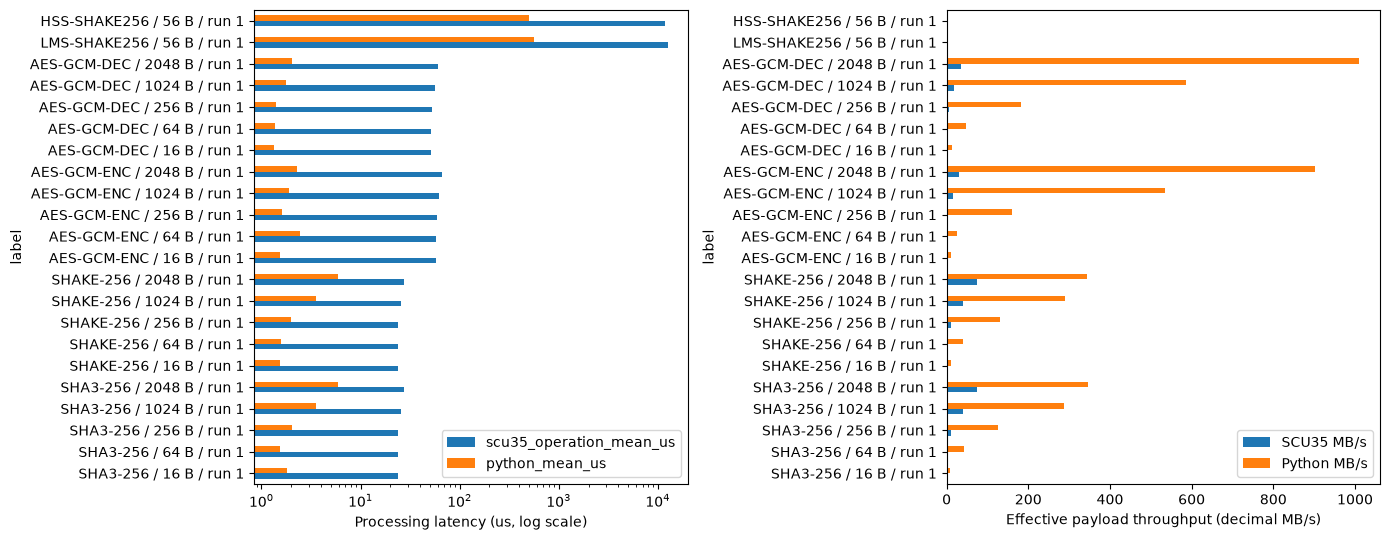

RECORDED HARDWARE + FRESH PYTHON: C:\aiup\s35p2\notebook_replay\03e52960\comparison.html
PUF and RNG lifecycle/generation results (different Python comparability):


,feature,hardware_us,status,python_equivalent,note,run
0,TRNG-HRNG-SETUP,36289.120,PASS,OS RNG setup is a different service,Initialization + self-tests + instantiation,1
1,TRNG-DRNG-SETUP,36782.940,PASS,OS RNG setup is a different service,Initialization + self-tests + instantiation,1
2,TRNG-PTRNG-SETUP,36259.490,PASS,OS RNG setup is a different service,Initialization + self-tests + instantiation,1
3,PUF-REGISTER,337.150,PASS,No physical equivalent,Volatile helper/key lifecycle; not export or s...,1
4,PUF-AES-ENC,40.700,PASS,No physical equivalent,Volatile helper/key lifecycle; not export or s...,1
5,PUF-KEY-CLEAR,2.940,PASS,No physical equivalent,Volatile helper/key lifecycle; not export or s...,1
6,PUF-REGENERATE,568.210,PASS,No physical equivalent,Volatile helper/key lifecycle; not export or s...,1
7,PUF-AES-DEC,34.720,PASS,No physical equivalent,Volatile helper/key lifecycle; not export or s...,1
8,TRNG-HRNG / 32 bytes,1623.515,20 successful calls; output length/nonzero/cha...,os.urandom(32): 0.271 us mean,Different randomness service; outputs must not...,1
9,TRNG-DRNG / 32 bytes,6.950,20 successful calls; output length/nonzero/cha...,os.urandom(32): 0.271 us mean,Different randomness service; outputs must not...,1


Device processing rates exclude programming/UART/JTAG. They are not physical bus bandwidth measurements.


In [4]:
LIVE = False
REPEATS = 1
reports = runtime(live=LIVE, repeats=REPEATS, c=c,
                  on_line=LiveRows() if LIVE else None)
comparison = show_runtime(reports)


Continue with notebooks 01?05 to rerun and explain individual feature groups; each can independently invoke this same hardware/Python flow. Notebook 08 benchmarks the shared IPI runtime, 06?07 handle image signing/encryption, and 09 inspects current PDI/PLM files. Device operation timing excludes host programming, transport and recovery. PUF has no physical Python equivalent; boot counters are not instrumented; eFUSE provisioning is excluded.